# A learned inverse map and its test set

**Level 1 — Foundations**  
**Prerequisites:** Python basics; 35 min.

## Objectives

Trace the evidence from source contract to result. State units and assumptions, reproduce the calculation, and identify which inference the evidence cannot support.

## Setup

Uses repository modules and committed records through a discovered root; it downloads and mutates nothing. Install exact pins: `pip install numpy==2.2.6 matplotlib==3.10.8`

## Data

Training ledger stores splits, normalized test errors, model metrics and a separately evaluated OOD control.

## Method

M12 predicts a depth-integrated density column from gravity-derived inputs; its target is not a 3D model. The ledger uses 800/160/160 train/validation/test realizations, disjoint generator seeds and withholds oblique/ring geometries from training. Classical and CNN estimates share 160 test cases. Their stored MSEs are 1466.24 and 680.15 `(g·cm⁻³·m)²`. Reconstruct paired per-case CNN errors using the declared target scale squared, plot classical-vs-CNN errors and the paired difference, and report fraction improved and median gain. This tests one synthetic generator and split design, not field geology, acquisition shifts or uncertainty calibration; averages can conceal regressions.

Paired test errors control case difficulty, but 160 realizations still sample the generator, not independent natural geology. CNN errors are normalized and require target-scale squared for physical MSE. Split by realization to prevent related samples leaking; a new site/sensor is a stronger transfer test. Do not select OOD threshold on OOD labels.

## Results

Read the physical axes and units; distinguish data fit, error against synthetic truth and agreement with analyst labels. Recomputed values must agree with the serialized receipt. A plotted model alone does not establish uniqueness, field transfer or resolution.

### Diagnostic 1

Inspect the committed case record and provenance.

In [1]:
from pathlib import Path
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'matplotlib']})
import numpy as np
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
# Load paired test errors and undo the ledger's declared CNN target normalization.
import json
from pathlib import Path
d=json.loads((root/"data/derived/v2/models/training.json").read_text(encoding="utf-8")); a=np.asarray(d["classical_test_errors"],float); b=np.asarray(d["models"]["cnn"]["test_errors"],float)*d["target_scale"]**2
print("splits",d["split_counts"],d["split_policy"],"cases",len(a),"unit",d["units"],"stored MSE",d["classical_test_mse"],d["cnn_test_mse"],"recomputed",a.mean(),b.mean())

Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
splits [800, 160, 160] Disjoint generator seeds; complete realization assigned to one split; oblique and ring geometries withheld from training cases 160 unit (g/cm³ m)² stored MSE 1466.238180685992 680.1517307758331 recomputed 1466.2381806859917 680.1517185231205


### Diagnostic 2

Compute the declared comparison and plot it with physical units.

CNN better fraction 0.8625 median gain 488.09731610902963 (g/cm³ m)²


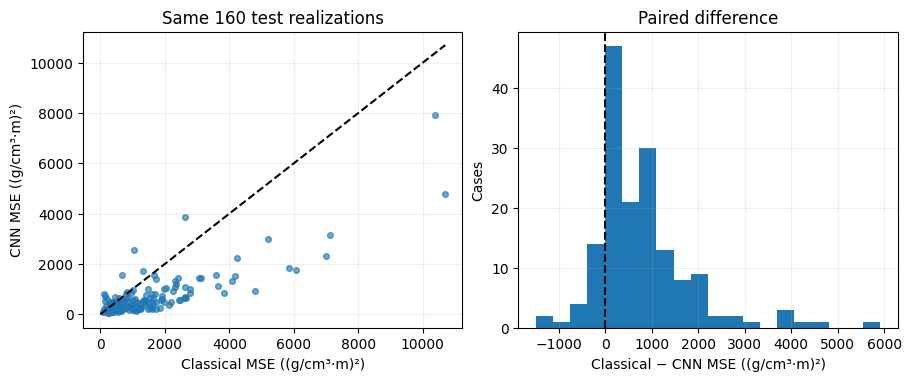

In [2]:
import numpy as np
import matplotlib.pyplot as plt
# Compare paired errors; points below the diagonal are cases where CNN MSE is lower.
import matplotlib.pyplot as plt
delta=a-b; lim=max(a.max(),b.max()); fig,ax=plt.subplots(1,2,figsize=(9,3.7),constrained_layout=True); ax[0].scatter(a,b,s=17,alpha=.65); ax[0].plot([0,lim],[0,lim],"k--"); ax[0].set(xlabel="Classical MSE ((g/cm³·m)²)",ylabel="CNN MSE ((g/cm³·m)²)",title="Same 160 test realizations"); ax[1].hist(delta,bins=20); ax[1].axvline(0,color="black",ls="--"); ax[1].set(xlabel="Classical − CNN MSE ((g/cm³·m)²)",ylabel="Cases",title="Paired difference"); [x.grid(alpha=.2) for x in ax]; print("CNN better fraction",(delta>0).mean(),"median gain",np.median(delta),d["units"]); plt.show()

## Summary

Conclusion is conditional on geometry, acquisition, noise model, split, parameterization and source rights. Preserve negative cases and name the next observation or control needed.

## References

- [https://doi.org/10.1093/gji/ggy423](https://doi.org/10.1093/gji/ggy423)
- [https://github.com/AI4EPS/PhaseNet](https://github.com/AI4EPS/PhaseNet)
- [https://github.com/lanl/OpenFWI](https://github.com/lanl/OpenFWI)